Dataset (number 14): https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand


###**Installing common libraries (Cài đặt các thư viện chung)**

In [ ]:
import pandas as pd
import numpy as np
import os
import torch
import shutil
import os
import gc

In [ ]:
!pip install pytorch-tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.5 MB/s eta 0:00:00


In [ ]:
!pip install pytorch-tabular

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.8/165.8 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 71.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.8/159.8 kB 18.4 MB/s eta 0:00:00


In [ ]:
!pip install cudf-cu12 cuml-cu12 --extra-index-url=https://pypi.nvidia.com

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 203.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-cuda-nvcc-cu12
    Found existing installation: nvidia-cuda-nvcc-cu12 12.5.82
    Uninstalling nvidia-cuda-nvcc-cu12-12.5.82:
      Successfully uninstalled nvidia-cuda-nvcc-cu12-12.5.82


###**Configuration Settings (Cài đặt cấu hình)**

In [ ]:
# Config task 1 (Selecting data and EDA)
config_task_1 = {
    # 1. Define data
    "dataset_code": "jessemostipak/hotel-booking-demand",

    # 2. Reproducibility (Tham số chia tách)
    "test_size": 0.2,
    "random_state": 42,

    # 3. Define target colum and delete some column affecting train (Tránh Data Leakage)
    "target_column": "is_canceled",
    "columns_to_drop": ["reservation_status", "reservation_status_date", "arrival_date_year", "company"], #Loại bỏ reservation_status, reservation_status_date và arrival_date_year bởi vì nếu có những này thì ta có thể chắc chắn đoán được output, Loại bỏ company

    # 4. Output location
    "feature_output_path_train": "X_train_raw.npy",
    "label_output_path_train": "y_train_raw.npy",
    "feature_output_path_test": "X_test_raw.npy",
    "label_output_path_test": "y_test_raw.npy",

    # 5. Configure the noise level of the data (Cấu hình độ "bẩn" của dữ liệu)
    "inject_missing_values": True,
    "missing_ratio": 0.05,
    "cols_to_inject_missing": ["lead_time", "adr", "market_segment"]
}

# Config task 2 (Preprocessing data)
config_task_2 = {
    # 1. Imputer: 'mean', 'median', 'most_frequent', 'constant'
    "num_impute_strategy": "median",
    "cat_impute_strategy": "constant",
    "cat_fill_value": "Unknown",

    # 2. Scaler: 'standard', 'minmax'
    "scaler_type": "standard",
    "minmax_range": (0, 1), # Only use if minmax is selected

    # 3. Encoder: 'onehot', 'label'
    "encoder_type": "onehot",

    # 4. PCA: Retained variance ratio (Tỉ lệ phương sai giữ lại: 0.9, 0.95, ...)
    "pca_variance": 0.95,

    # 5. Output localation for modern and tradition
    "feature_output_path_train_modern": "X_train_for_modern_model.npy",
    "feature_output_path_test_modern": "X_test_for_modern_model.npy",
    "feature_output_path_train_tradition": "X_train_for_traditional_model.npy",
    "feature_output_path_test_tradition": "X_test_for_traditional_model.npy",
}

###**Task 1: Data Collection and EDA (Thu thập data và EDA)**

In [ ]:
import kagglehub
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Data collection (Thu thập data)
def load_cultural_data(dataset_code):
    path = kagglehub.dataset_download(dataset_code)

    files = [f for f in os.listdir(path) if f.endswith('.csv')]
    data_path = os.path.join(path, files[0])
    df = pd.read_csv(data_path)

    print(f"- Data is saved in: {data_path}")
    return df

df = load_cultural_data(config_task_1["dataset_code"])
df.columns = df.columns.str.strip()   # Remove extra spaces from column names.

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
- Data is saved in: /kaggle/input/hotel-booking-demand/hotel_bookings.csv


In [ ]:
def step_1_overview(df):
    print(f"- The size of data: {df.shape}")
    print("\n- Columns and data types:")
    print(df.info())

In [ ]:
def step_2_check_missdata(df):
    plt.figure(figsize=(12, 5))
    sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
    plt.title("Missing data map (Yellow = Missing)")
    plt.show()

    missing_data = df.isnull().sum()
    if missing_data.sum() > 0:
      print("\n- Columns with missing data:\n")
      print(missing_data[missing_data > 0])


In [ ]:
def step_3_univariate_analysis(df):
    # 1 Analyzing target variable (Biến mục tiêu)
    plt.figure(figsize=(6, 4))
    sns.countplot(
        x=config_task_1["target_column"],
        data=df,
        hue=config_task_1["target_column"],
        palette='Set2',
        legend=False
    )
    plt.title("Target Variable Distribution (is_canceled)")
    plt.show()

    # 2 Analyzing numerical variable (Biến số)
    num_cols = [
        'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
        'adults', 'children', 'adr', 'total_of_special_requests',
        'previous_cancellations', 'days_in_waiting_list'
    ]
    # 2.1 Draw Histogram - check distribution (kiểm tra phân phối)
    df[num_cols].hist(figsize=(16, 12), bins=40, color='skyblue', edgecolor='black')
    plt.suptitle("Histogram: Distribution of variables", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    # 2.2 Draw Boxplot - check outliers (Kiểm tra Outliers)
    fig, axes = plt.subplots(3, 3, figsize=(16, 12))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightgreen')
        axes[i].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

    # 2.3 Descriptive statistics for the variable (Thống kê mô tả cho biến số)
    print("\n- Descriptive statistics for the variable:")
    display(df[num_cols].describe())

    # 3. Analyzing categorical variable (Biến phân loại)
    cat_cols = [
        'hotel', 'arrival_date_month', 'meal', 'market_segment',
        'distribution_channel', 'deposit_type', 'customer_type', 'is_repeated_guest'
    ]

    # 3.1 Draw a bar chart for categorical variables (Vẽ biểu đồ cột cho các biến phân loại)
    fig, axes = plt.subplots(4, 2, figsize=(16, 20))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):
        # Arranged in descending order for easier viewing.
        order = df[col].value_counts().index
        sns.countplot(
            x=col, data=df, ax=axes[i], order=order,
            hue=col, palette='viridis', legend=False
        )
        axes[i].set_title(f"Frequency of {col}")
        axes[i].tick_params(axis='x', rotation=45)

        # Add quantity labels at the top of each column.
        for p in axes[i].patches:
            axes[i].annotate(f'{int(p.get_height())}',
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha = 'center', va = 'center',
                             xytext = (0, 9),
                             textcoords = 'offset points',
                             fontsize=10)

    plt.tight_layout()
    plt.show()

    # 3.2 The 'country' column is handled separately due to the high number of values ​​(High Cardinality).
    print("\n- Top 10 countries with the most visitors:")
    top_10_countries = df['country'].value_counts().head(10)
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=top_10_countries.index, y=top_10_countries.values,
        hue=top_10_countries.index, palette='magma', legend=False
    )
    plt.title("Top 10 countries with the most visitors")
    plt.ylabel("Quantity")
    plt.show()

In [ ]:
def step_4_bivariate_analysis_and_multivariate_analysis(df):
    # 1. Cancellation Rate by Market Segment & Customer Type (Instead of looking at the count, we look at the percentage to clearly see which segment is the "riskiest")
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    # Market segmentation
    market_cancel_rate = df.groupby('market_segment')['is_canceled'].mean().sort_values(ascending=False)
    sns.barplot(x=market_cancel_rate.index, y=market_cancel_rate.values, ax=axes[0], palette='Reds_r', hue=market_cancel_rate.index, legend=False)
    axes[0].set_title("Cancellation Rate by Market Segment")
    axes[0].set_ylabel("Cancellation Rate (0.0 - 1.0)")

    # Customer type
    customer_cancel_rate = df.groupby('customer_type')['is_canceled'].mean().sort_values(ascending=False)
    sns.barplot(x=customer_cancel_rate.index, y=customer_cancel_rate.values, ax=axes[1], palette='Blues_r', hue=customer_cancel_rate.index, legend=False)
    axes[1].set_title("Cancellation Rate by Customer Type")
    plt.show()

    # 2. Variable and Target Analysis (KDE Plot)
    # Lead time (the time before booking) has a huge impact on the likelihood of cancellation.
    plt.figure(figsize=(12, 5))
    sns.kdeplot(data=df[df['is_canceled'] == 0], x='lead_time', fill=True, label='Không hủy', color='teal')
    sns.kdeplot(data=df[df['is_canceled'] == 1], x='lead_time', fill=True, label='Hủy', color='orange')
    plt.title("Lead Time Distribution: Do guests cancel bookings early or late?")
    plt.legend()
    plt.show()

    # 3. Timeline Analysis
    # Arrange months in the correct calendar order
    months = ['January', 'February', 'March', 'April', 'May', 'June',
              'July', 'August', 'September', 'October', 'November', 'December']
    df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=months, ordered=True)

    plt.figure(figsize=(15, 6))
    sns.lineplot(x='arrival_date_month', y='is_canceled', hue='hotel', data=df, marker='o')
    plt.title("Fluctuation of room cancellation rates by month in the year")
    plt.ylabel("Average cancellation rate")
    plt.show()

    # 4. Multivariate Analysis: Lead Time vs ADR vs Is Canceled
    # Is a last-minute booking at a high price more likely to be cancelled?
    plt.figure(figsize=(12, 7))
    # We sample 2000 rows so the scatter plot isn't too dense
    sample_df = df.sample(2000, random_state=42)
    sns.scatterplot(data=sample_df, x='lead_time', y='adr', hue='is_canceled',
                    alpha=0.6, palette='coolwarm')
    plt.ylim(0, 500) # Limit ADRs to focus on the majority of the data.
    plt.title("Interaction between Lead Time, Average Daily Rate (ADR), and Cancellation.")
    plt.show()

    # 5.The relationship between special requests and room cancellations
    # Hypothesis: The more special requests a customer makes, the fewer cancellations they will have?
    plt.figure(figsize=(10, 5))
    sns.barplot(x='total_of_special_requests', y='is_canceled', data=df, palette='viridis', hue='total_of_special_requests', legend=False)
    plt.title("Cancellation rates are based on the number of special requests.")
    plt.show()

    # Correlation Matrix (Numerical only)
    plt.figure(figsize=(15, 10))
    numeric_cols = df.select_dtypes(include=[np.number])
    corr_matrix = numeric_cols.corr()
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
    plt.title("Correlation matrix between variables")
    plt.show()

In [ ]:
def step_5_cardinality(df):
    results = []
    for col in df.columns:
        n_unique = df[col].nunique()
        percent_unique = (n_unique / len(df)) * 100
        dtype = df[col].dtype

        top_values = df[col].value_counts().index[:5].tolist()

        results.append({
            "Column": col,
            "Type": dtype,
            "Unique_Values": n_unique,
            "Percentage_Unique (%)": round(percent_unique, 4),
            "Top_3_Values": top_values
        })

    card_df = pd.DataFrame(results)

    # 1. Constant columns detected - Each column has only one value, so delete it immediately.
    constants = card_df[card_df['Unique_Values'] <= 1]['Column'].tolist()
    if constants:
        print(f"- Warning: The following columns contain only one value (useless): {constants}")

    # 2. Detecting high CARDINALITY columns (Too many unique values)
    # Using One-Hot Encoding for these columns will cause a feature overload.
    high_card = card_df[(card_df['Unique_Values'] > 50) & (card_df['Type'] == 'object')]['Column'].tolist()
    if high_card:
        print(f"- High Cardinality Warning: {high_card} (Consider Label Encoding or Target Encoding instead of One-Hot)")

    # 3. Low cardinality numerical variable
    num_but_cat = card_df[(card_df['Unique_Values'] < 15) & (card_df['Type'] != 'object')]['Column'].tolist()
    if num_but_cat:
        print(f"- Variables with few values ​​(can be considered categorical): {num_but_cat}")

    display(card_df.sort_values(by="Unique_Values", ascending=False))

--- DETAILED EDA IS CURRENTLY BEING PERFORMED ---
Step 1 Overview
- The size of data: (119390, 32)

- Columns and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children      

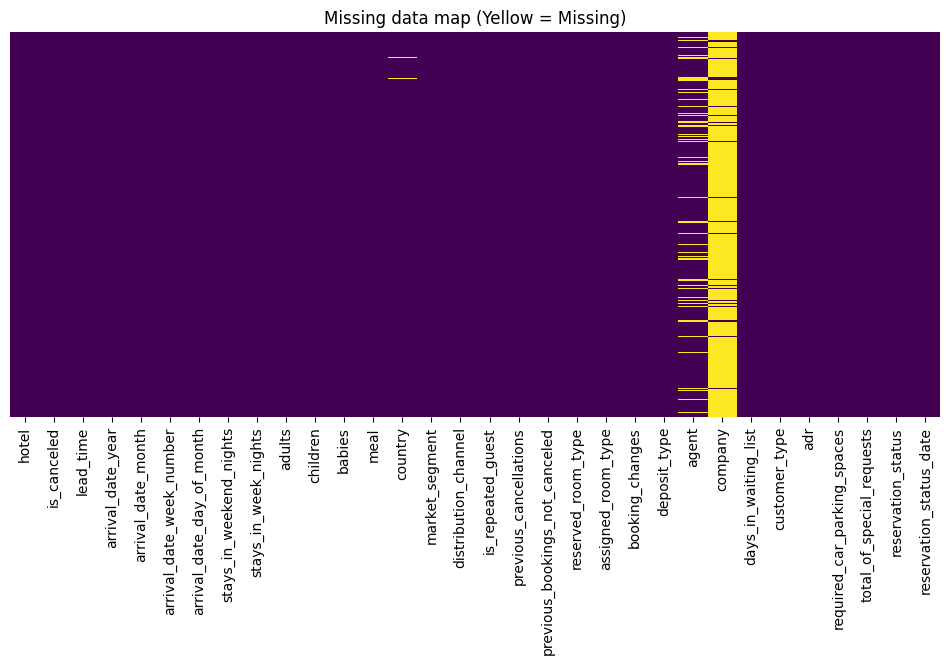


- Columns with missing data:

children         4
country        488
agent        16340
company     112593
dtype: int64
Step 3 Univariate Analysis


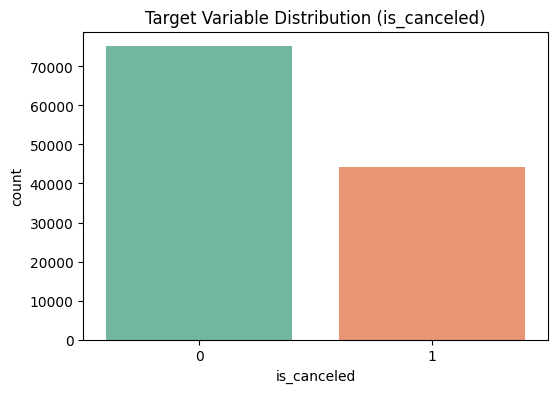

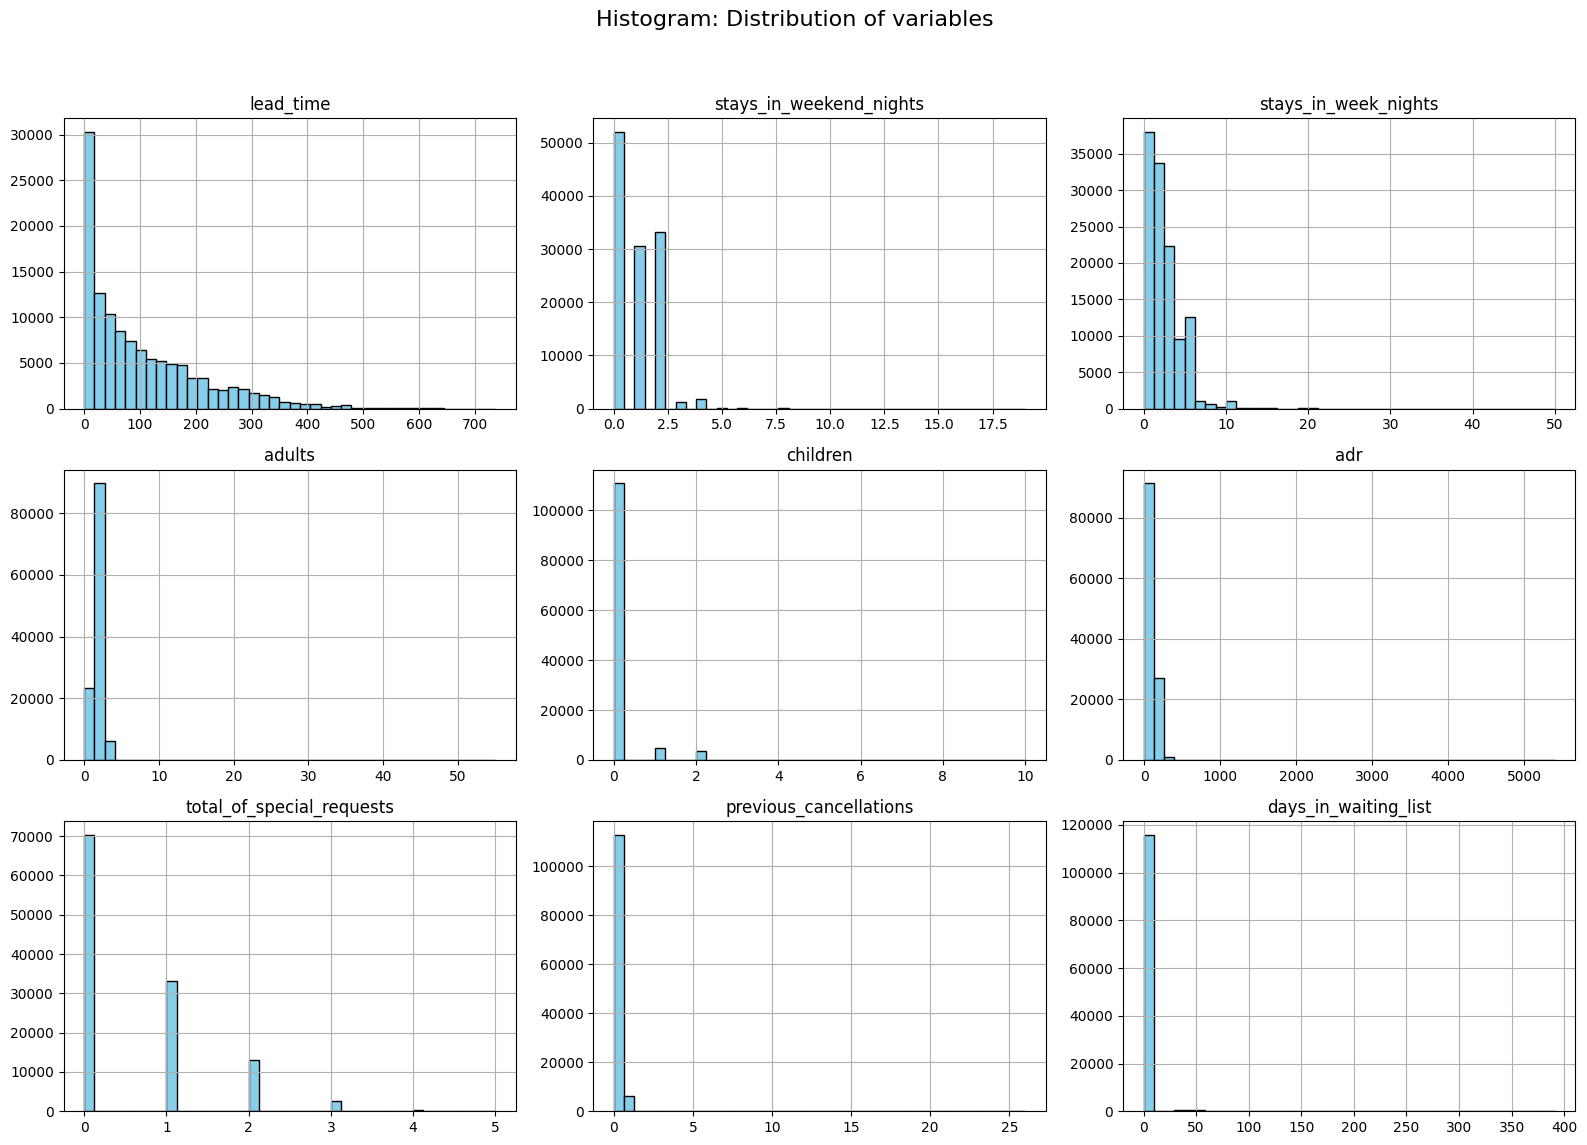

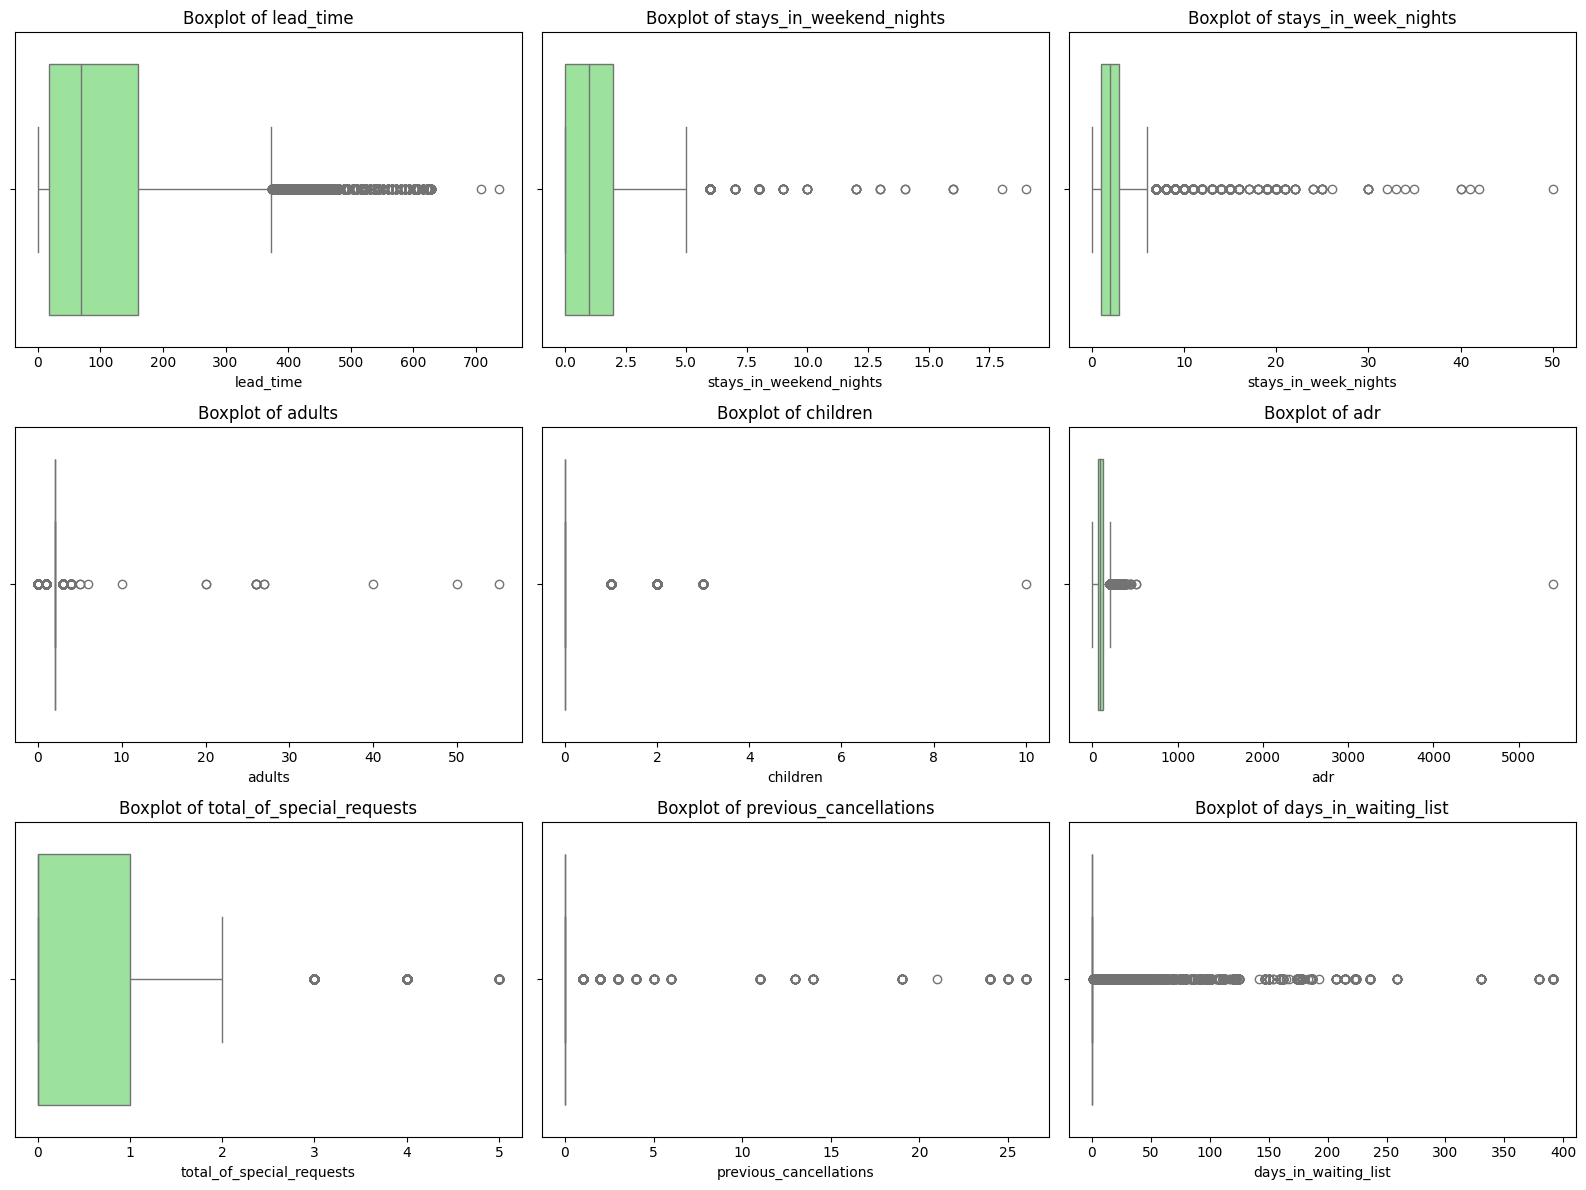


- Descriptive statistics for the variable:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,adr,total_of_special_requests,previous_cancellations,days_in_waiting_list
count,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,104.011416,0.927599,2.500302,1.856403,0.103890,101.831122,0.571363,0.087118,2.321149
std,106.863097,0.998613,1.908286,0.579261,0.398561,50.535790,0.792798,0.844336,17.594721
min,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,69.290000,0.000000,0.000000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,94.575000,0.000000,0.000000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,126.000000,1.000000,0.000000,0.000000
max,737.000000,19.000000,50.000000,55.000000,10.000000,5400.000000,5.000000,26.000000,391.000000


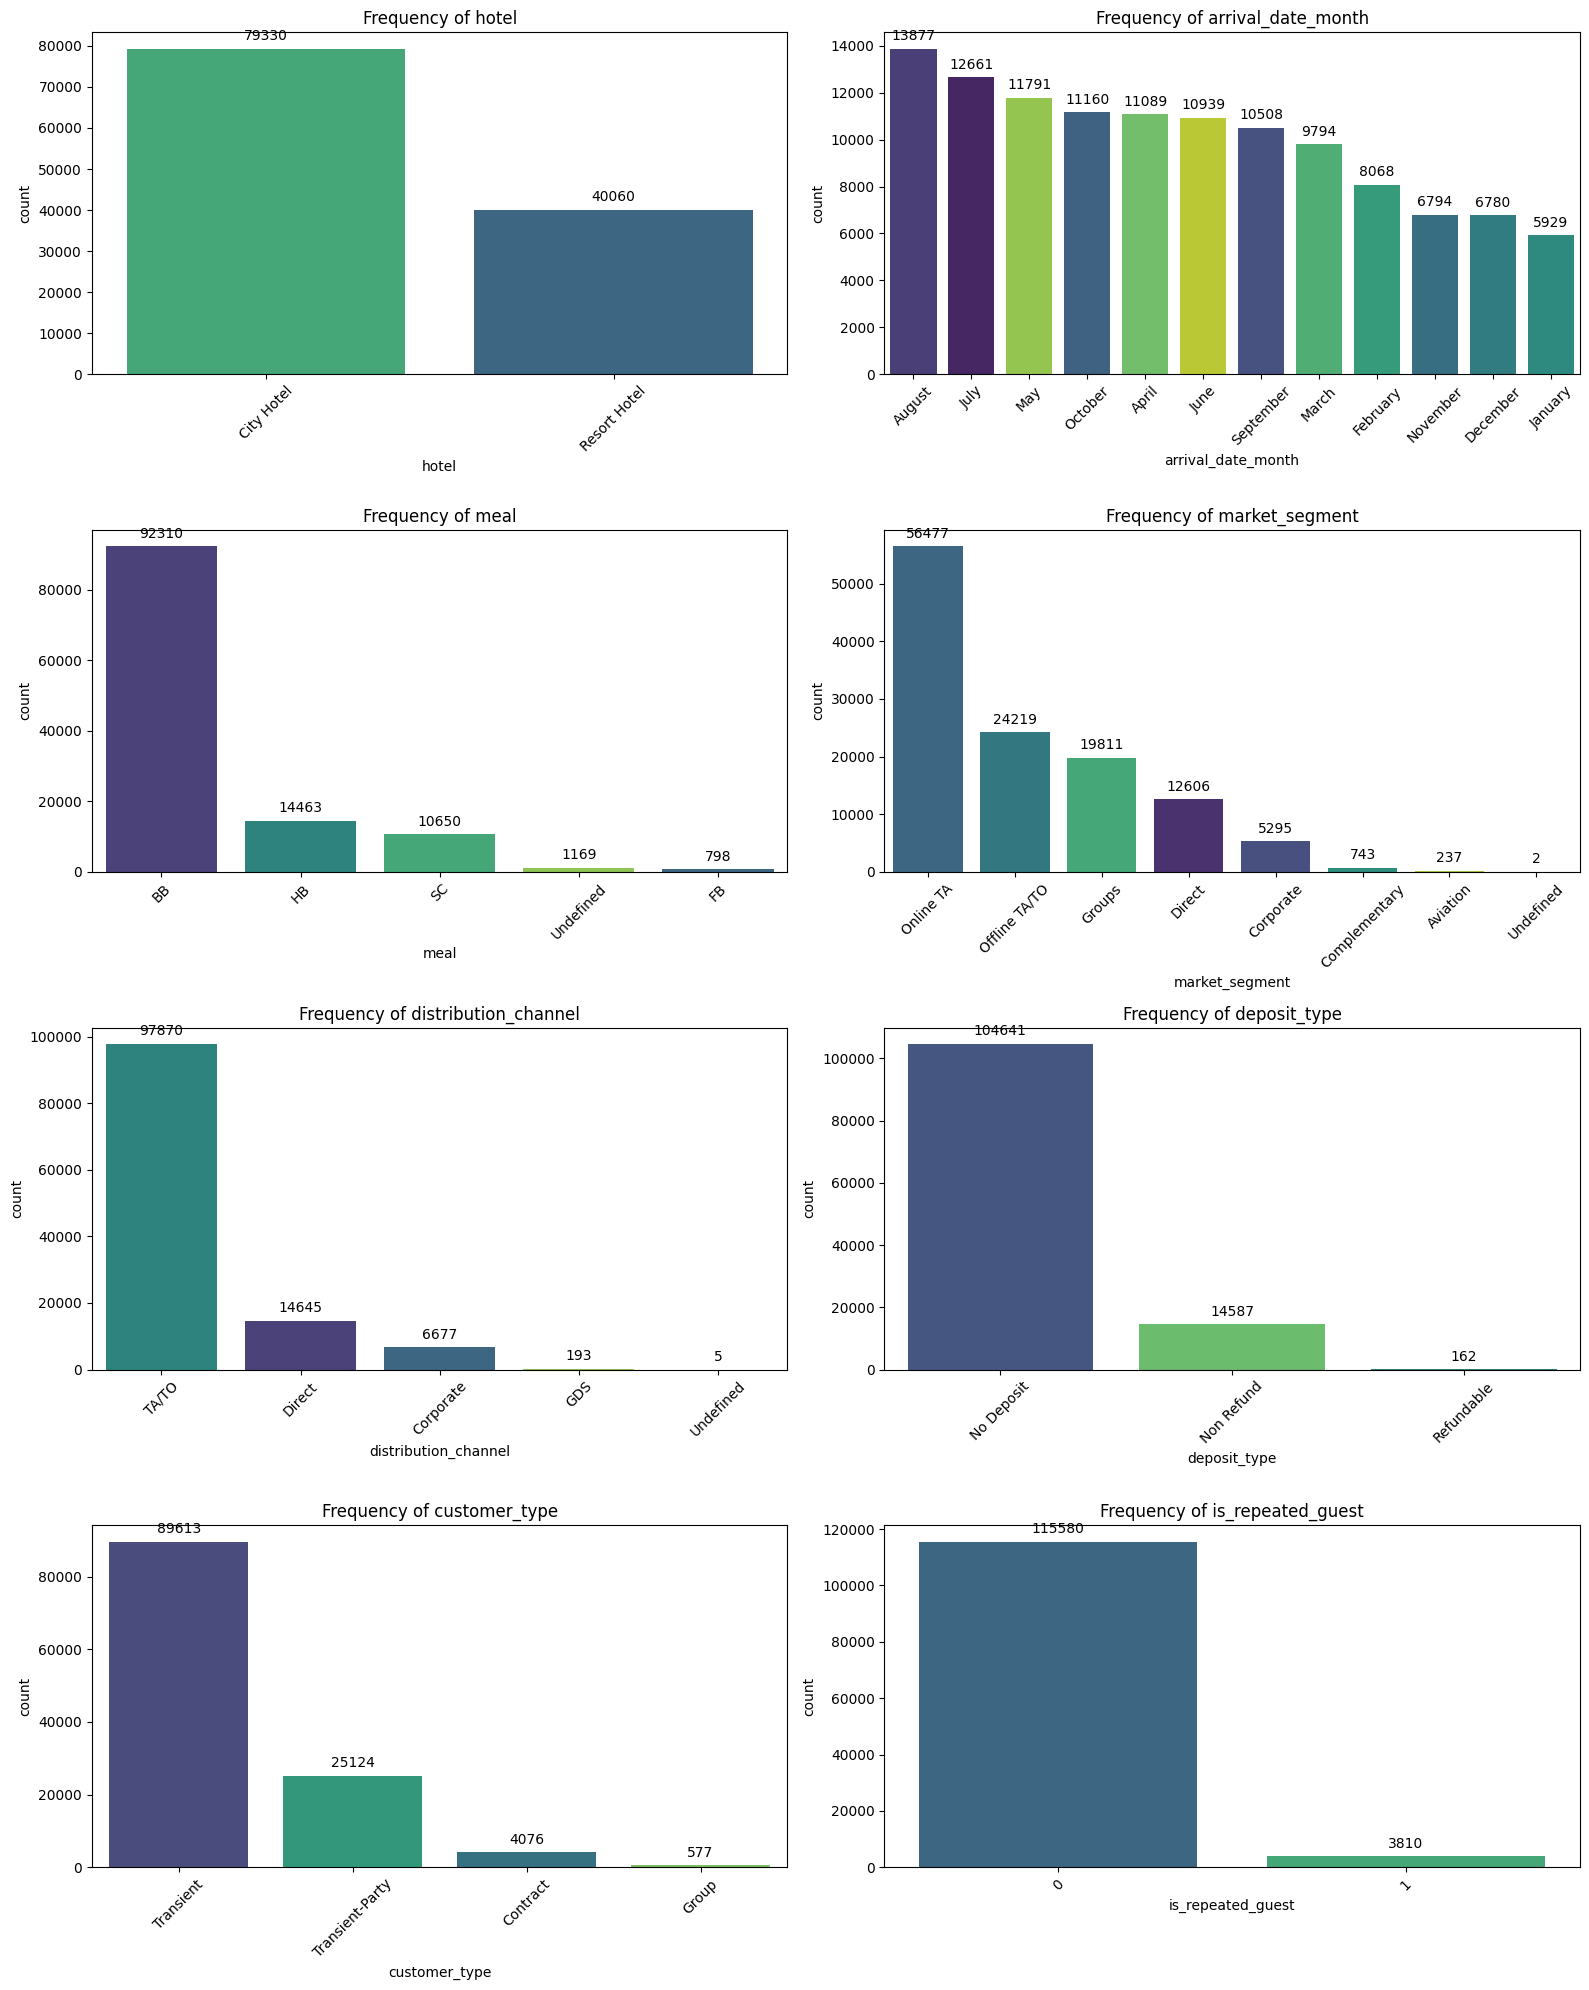


- Top 10 countries with the most visitors:


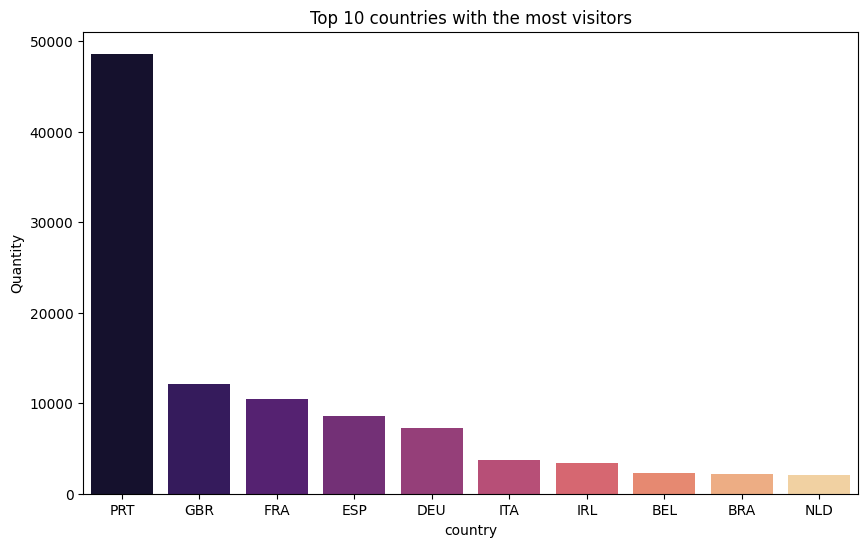

Step 4 Bivariate & Multivariate Analysis


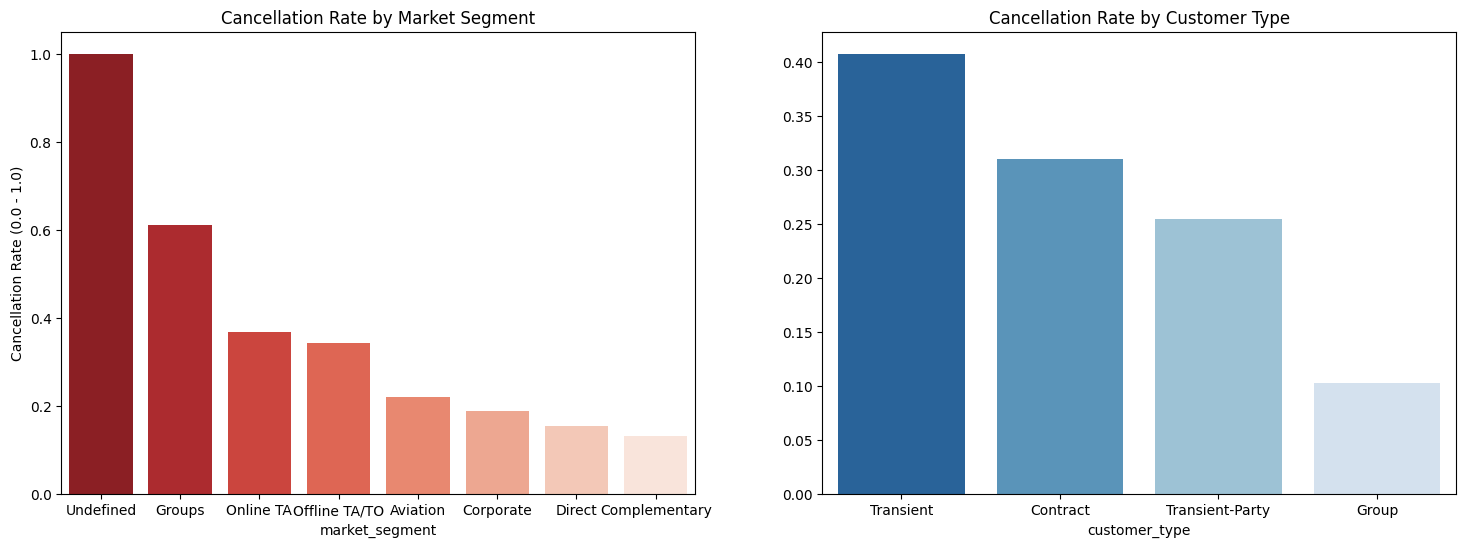

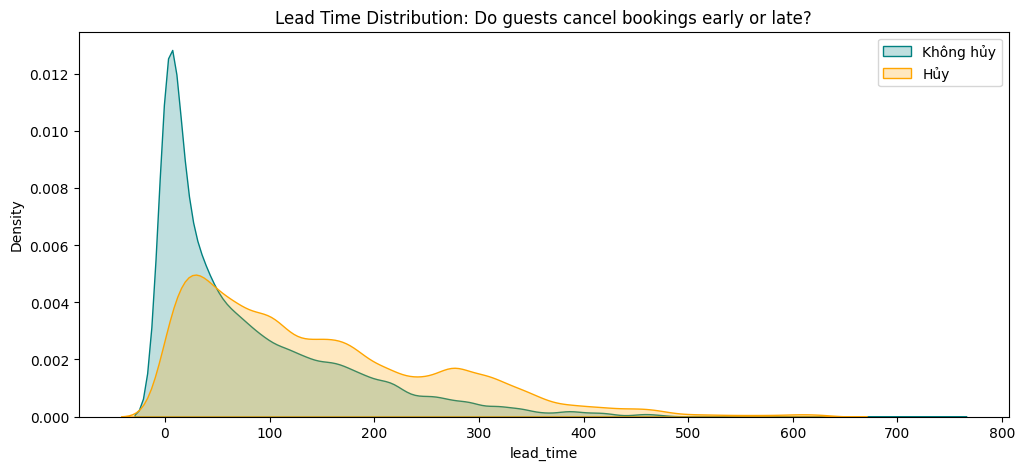

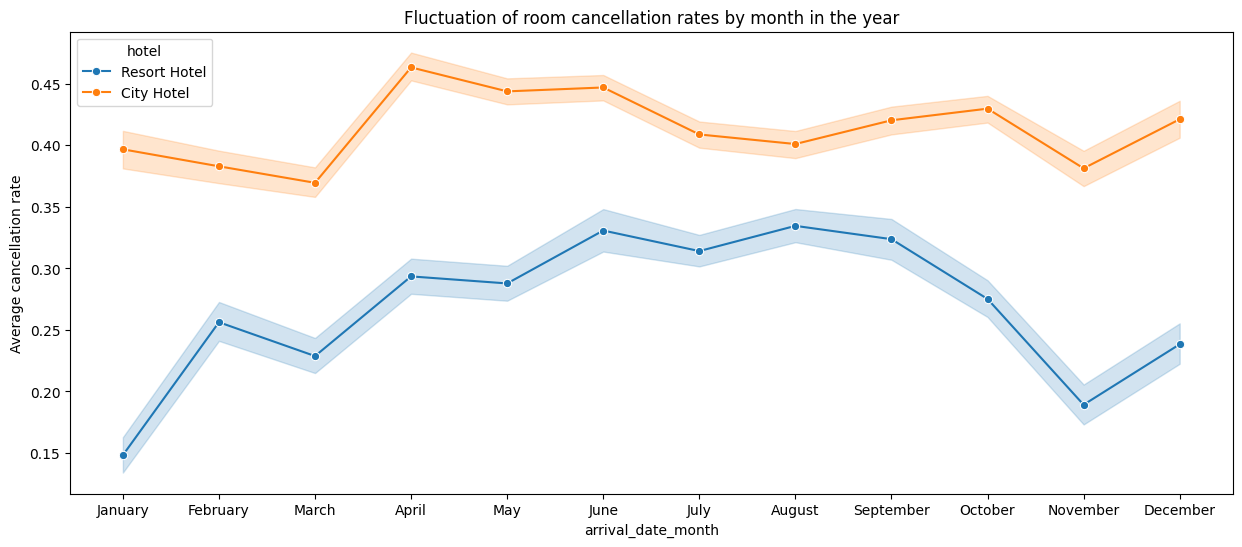

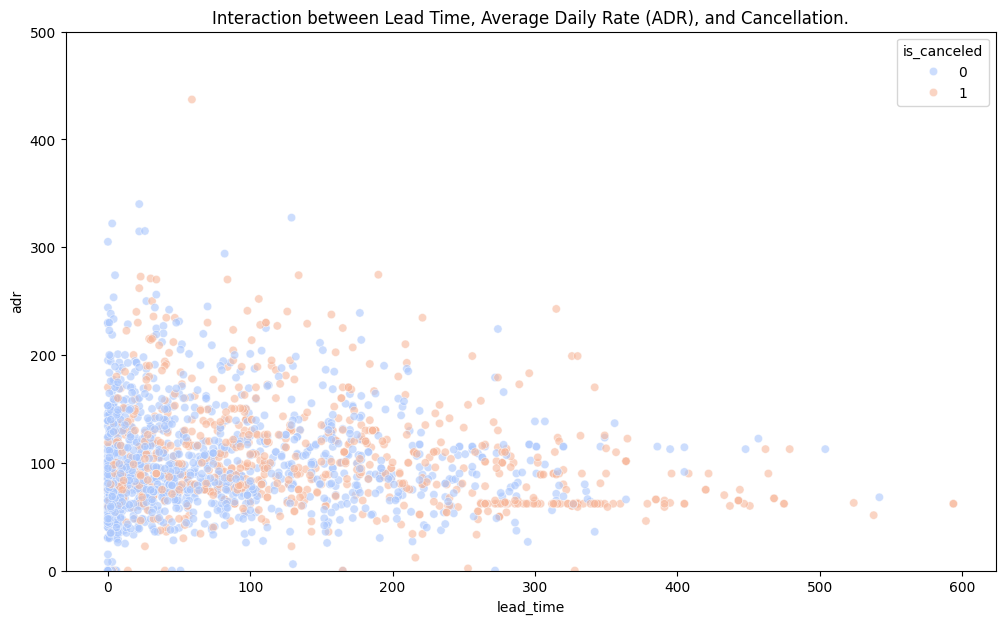

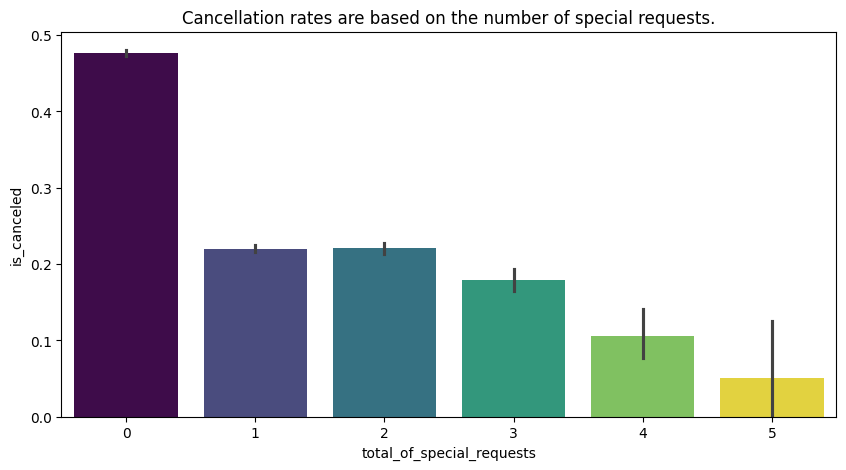

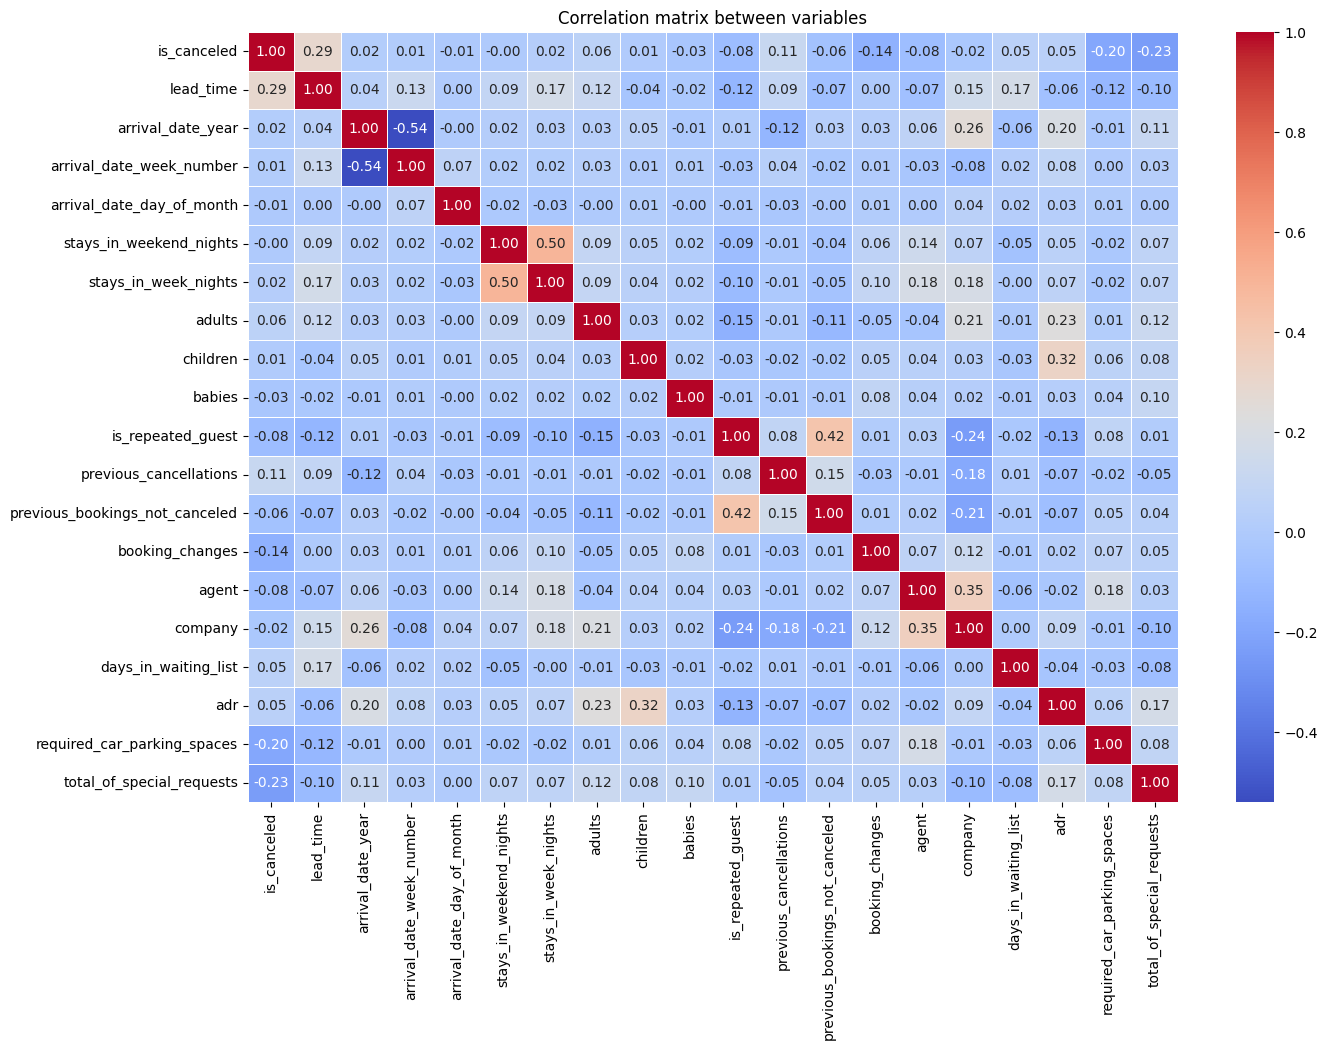

Step 5 Check Unique Categorical Data
- High Cardinality Warning: ['country', 'reservation_status_date'] (Consider Label Encoding or Target Encoding instead of One-Hot)
- Variables with few values ​​(can be considered categorical): ['is_canceled', 'arrival_date_year', 'arrival_date_month', 'adults', 'children', 'babies', 'is_repeated_guest', 'required_car_parking_spaces', 'total_of_special_requests']


,Column,Type,Unique_Values,Percentage_Unique (%),Top_3_Values
27,adr,float64,8879,7.4370,"[62.0, 75.0, 90.0, 65.0, 0.0]"
31,reservation_status_date,object,926,0.7756,"[2015-10-21, 2015-07-06, 2016-11-25, 2015-01-0..."
2,lead_time,int64,479,0.4012,"[0, 1, 2, 3, 4]"
24,company,float64,352,0.2948,"[40.0, 223.0, 67.0, 45.0, 153.0]"
23,agent,float64,333,0.2789,"[9.0, 240.0, 1.0, 14.0, 7.0]"
13,country,object,177,0.1483,"[PRT, GBR, FRA, ESP, DEU]"
25,days_in_waiting_list,int64,128,0.1072,"[0, 39, 58, 44, 31]"
18,previous_bookings_not_canceled,int64,73,0.0611,"[0, 1, 2, 3, 4]"
5,arrival_date_week_number,int64,53,0.0444,"[33, 30, 32, 34, 18]"
8,stays_in_week_nights,int64,35,0.0293,"[2, 1, 3, 5, 4]"


In [ ]:
#Exploratory Data Analysis (EDA)
def perform_eda(df):
    print("--- DETAILED EDA IS CURRENTLY BEING PERFORMED ---")

    # Step 1: Structural overview (TỔNG QUAN CẤU TRÚC)
    print("=" * 150)
    print("Step 1 Overview")
    print("=" * 150)
    step_1_overview(df)

    # Step 2. Check missing data (KIỂM TRA DỮ LIỆU THIẾU)
    print("=" * 150)
    print("Step 2 Check Missing Data")
    print("=" * 150)
    step_2_check_missdata(df)

    # Step 3. Univariate Analysis (PHÂN TÍCH ĐƠN BIẾN)
    print("=" * 150)
    print("Step 3 Univariate Analysis")
    print("=" * 150)
    step_3_univariate_analysis(df)

    # Step 4. Bivariate & Multivariate (PHÂN TÍCH SONG BIẾN & ĐA BIẾN)
    print("=" * 150)
    print("Step 4 Bivariate & Multivariate Analysis")
    print("=" * 150)
    step_4_bivariate_analysis_and_multivariate_analysis(df)

    # Step 5. Check cardinality (KIỂM TRA TÍNH DUY NHẤT)
    print("=" * 150)
    print("Step 5 Check Unique Categorical Data")
    print("=" * 150)
    step_5_cardinality(df)

perform_eda(df)

###**Task 2: Preprocesing Data (Tiền xử lí dữ liệu)**

In [ ]:
def initialize_task_2(df):
    # 1. Creating data lacking simulation (Tạo dữ liệu thiếu giả lập)
    if config_task_1["inject_missing_values"]:
        np.random.seed(config_task_1["random_state"])
        for col in config_task_1["cols_to_inject_missing"]:
            if col in df.columns:
                mask = np.random.rand(len(df)) < config_task_1["missing_ratio"]
                df.loc[mask, col] = np.nan

    # 2. Data preprocessing-removing missing data (Tiền xử lí data - loại bỏ các missing data)
    # 2.1 Handling Children: Dropping 4 lines is impractical, keeping children under 10, forcing int type.
    df = df.dropna(subset=['children'])
    df = df[df['children'] < 10]
    df['children'] = df['children'].astype(int)

    # 2.2 Agent handling: Null is equivalent to placing it directly -> enter 0
    df['agent'] = df['agent'].fillna(0)

    # 2.3 Clean up consistency: Handle invalid and non-physical records.
    df = df[(df['adults'] + df['children'] + df['babies']) > 0]
    df = df[df['adults'] <= 10]
    df = df[df['babies'] < 8]

    # 2.4 Handling extreme Outlier ADRs from Boxplot (> 5000)
    df = df[df['adr'] < 5000]

    # 2.5 Key technique: Convert Previous Cancellations to Binary
    df['is_previously_canceled'] = (df['previous_cancellations'] > 0).astype(int)

    # 2.6. High Cardinality treatment for 'country': Keep Top 10 + Other
    top_10_countries = df['country'].value_counts().nlargest(10).index
    df['country'] = df['country'].apply(lambda x: x if x in top_10_countries else 'Other')

    # 2.7 Remove Leakage columns before saving.
    extra_drops = ["previous_cancellations"]
    drop_list = list(set(config_task_1["columns_to_drop"] + extra_drops))
    df_final = df.drop(columns=[c for c in drop_list if c in df.columns])

    # 3. Splitting the dataset
    from sklearn.model_selection import train_test_split
    X = df_final.drop(columns=[config_task_1["target_column"]])
    y = df_final[config_task_1["target_column"]]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=config_task_1["test_size"], random_state=config_task_1["random_state"]
    )

    # 4. Save the feature file (.npy)
    # Since the data is still Categorical (in string format), we save it as an Object array.
    np.save(config_task_1["feature_output_path_train"], X_train.values)
    np.save(config_task_1["label_output_path_train"], y_train.values)
    np.save(config_task_1["feature_output_path_test"], X_test.values)
    np.save(config_task_1["label_output_path_test"], y_test.values)

    print(f"\n- Save file: {config_task_1['feature_output_path_train']}")
    print(f"- The size of Train data: {X_train.shape} {y_train.shape}")
    print(f"- The size of Test data: {X_test.shape} {y_test.shape}")
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = initialize_task_2(df)


- Save file: X_train_raw.npy
- The size of Train data: (90689, 27) (90689,)
- The size of Test data: (22673, 27) (22673,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA

In [ ]:
def build_preprocessing_pipeline(num_features, cat_features, type):
    # A. Numerical data processing branch (Nhánh xử lý dữ liệu SỐ)
    num_scaler = StandardScaler() if config_task_2["scaler_type"] == "standard" \
                 else MinMaxScaler(feature_range=config_task_2["minmax_range"])

    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy=config_task_2["num_impute_strategy"])),
        ('scaler', num_scaler)
    ])

    # B. The Categorical data processing branch (Nhánh xử lý dữ liệu PHÂN LOẠI)
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(
            strategy=config_task_2["cat_impute_strategy"],
            fill_value=config_task_2.get("cat_fill_value", "Unknown")
        )),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # C. Merge two branches using ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_features),
            ('cat', cat_transformer, cat_features)
        ]
    )
    # D. PCA
    if type == "tradition":

      full_pipeline = Pipeline(steps=[
          ('preprocessor', preprocessor),
          ('pca', PCA(n_components=config_task_2["pca_variance"]))
      ])
      return full_pipeline

    return preprocessor

In [ ]:
all_columns = X_train.columns.tolist()

num_cols_names = [
    'lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month',
    'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
    'babies', 'is_previously_canceled', 'adr', 'required_car_parking_spaces', 'agent'
]

num_feature_idx = [all_columns.index(col) for col in num_cols_names if col in all_columns]
cat_feature_idx = [i for i in range(len(all_columns)) if i not in num_feature_idx]

# 1. Preprocessing for Tradional Model
# 1.1 Initialize Pipeline (Khởi tạo Pipeline)
pipeline = build_preprocessing_pipeline(num_feature_idx, cat_feature_idx, "tradition")

# 1.2. Reload X_raw (Load lại X_raw - lúc này đã sạch và có cột mới)
X_raw_train_tradition = np.load(config_task_1["feature_output_path_train"], allow_pickle=True)
X_raw_test_tradition = np.load(config_task_1["feature_output_path_test"], allow_pickle=True)

# 1.3. Training and transformation (Huấn luyện và chuyển đổi)
# Note: Fit only during training sessions.
X_processed_train_tradition = pipeline.fit_transform(X_raw_train_tradition)
X_processed_test_tradition = pipeline.transform(X_raw_test_tradition)

print(f"-- Preprocessing traditional model complete! --")
print(f"- Data size train after preprocessing (PCA): {X_processed_train_tradition.shape}")
print(f"- Data size test after preprocessing (PCA): {X_processed_test_tradition.shape}")

# 1.4. Save result
np.save(config_task_2["feature_output_path_train_tradition"], X_processed_train_tradition)
np.save(config_task_2["feature_output_path_test_tradition"], X_processed_test_tradition)

# 2 Preprocessing for Modern Model
# 2.1 Initialize Pipeline (Khởi tạo Pipeline)
pipeline = build_preprocessing_pipeline(num_feature_idx, cat_feature_idx, "modern")

# 2.2. Reload X_raw (Load lại X_raw - lúc này đã sạch và có cột mới)
X_raw_train_modern = np.load(config_task_1["feature_output_path_train"], allow_pickle=True)
X_raw_test_modern = np.load(config_task_1["feature_output_path_test"], allow_pickle=True)

# 2.3. Training and transformation (Huấn luyện và chuyển đổi)
# Note: Fit only during training sessions.
X_processed_train_modern = pipeline.fit_transform(X_raw_train_modern)
X_processed_test_modern = pipeline.transform(X_raw_test_modern)

print()
print(f"-- Preprocessing modern model complete! --")
print(f"- Data size train after preprocessing: {X_processed_train_modern.shape}")
print(f"- Data size test after preprocessing: {X_processed_test_modern.shape}")

# 2.4. Save result
np.save(config_task_2["feature_output_path_train_modern"], X_processed_train_modern)
np.save(config_task_2["feature_output_path_test_modern"], X_processed_test_modern)


-- Preprocessing traditional model complete! --
- Data size train after preprocessing (PCA): (90689, 39)
- Data size test after preprocessing (PCA): (22673, 39)

-- Preprocessing modern model complete! --
- Data size train after preprocessing: (90689, 296)
- Data size test after preprocessing: (22673, 296)


###**Task 3: Train Traditional Model (Train các model truyền thống)**

In [ ]:
testcases = [
    {
        "id": 1,
        "description": "Baseline, Fast & Simple (Probably underfitting)",
        "params": {
            "LR": {"max_iter": 1000, "C": 0.1},
            "SVM": {"kernel": "linear", "C": 0.1}, # linear fast and simple
            "RF": {"n_estimators": 50, "max_depth": 5}
        }
    },
    {
        "id": 2,
        "description": "High capacity, Deep & Complex (Probably Overfitting)",
        "params": {
            "LR": {"max_iter": 2000, "C": 1.0},
            "SVM": {"kernel": "rbf", "C": 1.0}, # rbf: complex
            "RF": {"n_estimators": 150, "max_depth": 16}
        }
    },
    {
        "id": 3,
        "description": "Strong regularization to prevent overfitting",
        "params": {
            "LR": {"max_iter": 2000, "C": 0.01, "penalty":'l2'},
            "SVM": {"kernel": "rbf", "C": 0.01,"gamma":'scale'},
            "RF": {"n_estimators": 100, "max_depth": 10, "min_samples_split": 20}
        }
    },
    {
        "id": 4,
        "description": "Cost sensitive : Class Weight Balanced",
        "params": {
            "LR": {"class_weight": "balanced", "C": 1.0},
            "SVM": {"kernel": "rbf", "C": 1.0, "class_weight": "balanced"},
            "RF": {"n_estimators": 100, "max_depth": 16}
        }
    }
    # {"id": 5,
    #       "description": "Polynomial Kernel",
    #       "params": {
    #                 "LR": {"max_iter": 2000, "C": 1.0},
    #                 "SVM":{"kernel": "poly","degree":3, "C": 1.0},
    #                 "RF": {"n_estimators": 150, "max_depth": None}
    #       }
    # }
]

In [ ]:
all_model_results = []    # Where to save the final results for comparison (nơi lưu kết quả cuối cùng để so sánh)

In [ ]:
import cupy as cp
import cuml
from cuml.model_selection import train_test_split
from cuml.linear_model import LogisticRegression
from cuml.svm import SVC
from cuml.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load data from your existing .npy files (Load dữ liệu từ các file .npy bạn đang có)
X_train_tmp = np.load(config_task_2["feature_output_path_train_tradition"], allow_pickle=True)
X_test_tmp = np.load(config_task_2["feature_output_path_test_tradition"], allow_pickle=True)
y_train_tmp = np.load(config_task_1["label_output_path_train"], allow_pickle=True)
y_test_tmp = np.load(config_task_1["label_output_path_test"], allow_pickle=True)

# 2. Normalize data
X_train = cp.array(X_train_tmp).astype('float32')
X_test = cp.array(X_test_tmp).astype('float32')
y_train = cp.array(y_train_tmp).astype('float32')
y_test = cp.array(y_test_tmp).astype('float32')

# 3. Main loop
for case in testcases:
    print(f"\n" + "="*100)
    print(f"- RUN MODEL WITH PARAMETER CONFIG {case['id']}: {case['description']}")
    print("="*100)

    results = []

    models = [
        ("Logistic Regression", LogisticRegression(**case['params']['LR'])),
        ("SVM", SVC(**case['params']['SVM'])),
        ("Random Forest", RandomForestClassifier(**case['params']['RF'], random_state=42))
    ]

    for name, model in models:
        print(f"--- Trainning {name}...")

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred_gpu = model.predict(X_test)
        y_test_cpu = y_test.get()
        y_pred_cpu = y_pred_gpu.get()

        # Calculate accuracy, precision, recall and F1-score
        acc = accuracy_score(y_test_cpu, y_pred_cpu)
        pre = precision_score(y_test_cpu, y_pred_cpu, zero_division=0)
        rec = recall_score(y_test_cpu, y_pred_cpu, zero_division=0)
        f1 = f1_score(y_test_cpu, y_pred_cpu, zero_division=0)

        # Save result
        results.append({
            "Model": name,
            "Accuracy": acc,
            "Precision": pre,
            "Recall": rec,
            "F1-Score": f1
        })

        # Save final result
        all_model_results.append({
            "Source": f"Task 3 (TC {case['id']})",
            "Model Name": name,
            "Accuracy": acc,
            "Precision": pre,
            "Recall": rec,
            "F1-Score": f1
        })

    # 4. Summarizing result
    df_summary = pd.DataFrame(results)
    print(f"\n- SUMMARY TABLE {case['id']}:")
    print(df_summary.to_string(index=False))


- RUN MODEL WITH PARAMETER CONFIG 1: Baseline, Fast & Simple (Probably underfitting)
--- Trainning Logistic Regression...
--- Trainning SVM...
--- Trainning Random Forest...

- SUMMARY TABLE 1:
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.808318   0.806961 0.643084  0.715762
                SVM  0.811141   0.821543 0.634622  0.716085
      Random Forest  0.763066   0.983359 0.375015  0.542964

- RUN MODEL WITH PARAMETER CONFIG 2: High capacity, Deep & Complex (Probably Overfitting)
--- Trainning Logistic Regression...
--- Trainning SVM...
--- Trainning Random Forest...

- SUMMARY TABLE 2:
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.808274   0.806300 0.643789  0.715938
                SVM  0.848145   0.852982 0.719356  0.780491
      Random Forest  0.855423   0.895270 0.696204  0.783287

- RUN MODEL WITH PARAMETER CONFIG 3: Strong regularization to prevent overfitting
--- Trainning Logistic Regression...
--- T

###**Task 4: Train Modern Model (Train model hiện đại)**

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout, Add
from tensorflow.keras.optimizers import Adam, RMSprop, SGD, AdamW
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
X_train_processed = np.load(config_task_2["feature_output_path_train_modern"], allow_pickle=True)
X_test = np.load(config_task_2["feature_output_path_test_modern"], allow_pickle=True)
y_train_processed  = np.load(config_task_1["label_output_path_train"], allow_pickle=True)
y_test = np.load(config_task_1["label_output_path_test"], allow_pickle=True)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_processed,
    y_train_processed,
    test_size=0.1,
    random_state=config_task_1["random_state"]
)

print(f"--- The size of data of Modern Model ---")
print(f"Sum of Original Train: {X_train_processed.shape} {y_train_processed .shape}")
print(f"-> Partical Train: {X_train.shape} {y_train.shape}")
print(f"-> Validation:    {X_val.shape} {y_val.shape}")
print(f"-> Test: {X_test.shape} {y_test.shape}")

--- The size of data of Modern Model ---
Sum of Original Train: (90689, 296) (90689,)
-> Partical Train: (81620, 296) (81620,)
-> Validation:    (9069, 296) (9069,)
-> Test: (22673, 296) (22673,)


**Model multilayer perceptron (MLP)**

In [ ]:
deep_learing_config = {
    "input_shape": X_train.shape[1],
    "epochs": 50,
    "batch_size": 128,
}

In [ ]:
optimizers_dict = {
    'adam': Adam(learning_rate=1e-3),
    'rmsprop': RMSprop(learning_rate=1e-3),
    'sgd': SGD(learning_rate=1e-2, momentum=0.9),
    'adamw': AdamW(learning_rate=5e-4, weight_decay=1e-3, beta_1=0.9, beta_2=0.999)
}

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

callbacks_list = [early_stopping, reduce_lr]

In [ ]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(enumerate(class_weights))
print("Class Weights:", class_weight_dict)

Class Weights: {0: np.float64(0.7923348736069584), 1: np.float64(1.3551836355183635)}


In [ ]:
def build_optimized_model(input_dim):
    inputs = Input(shape=(input_dim,))

    # 1. Wider layer to capture more features
    x = Dense(256, activation='relu')(inputs)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    # 2. Residual Block (Bí quyết cho Tabular Data)
    res_1 = x # Lưu giữ thông tin ở lớp này
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Add()([x, res_1])

    # 3. Funneling
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)

    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)

    # Output
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=inputs, outputs=outputs)
    return model

In [ ]:
history_dict = {}
comparison_results = []
input_dim = X_train.shape[1]

for opt_name, opt_function in optimizers_dict.items():
    print(f"\n🔥 Training with Optimizers: {opt_name.upper()} (BCE + Class Weight)")

    model = build_optimized_model(input_dim)

    model.compile(optimizer=opt_function,
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(
        X_train, y_train,
        epochs=deep_learing_config["epochs"],
        batch_size=deep_learing_config["batch_size"],
        validation_data=(X_val, y_val),
        class_weight=class_weight_dict,
        callbacks=callbacks_list,
        verbose=0
    )

    history_dict[opt_name] = history

    y_val_probs = model.predict(X_val, verbose=0)
    best_threshold = 0.5
    best_f1 = 0

    for thresh in np.arange(0.3, 0.9, 0.001):
        val_pred = (y_val_probs > thresh).astype("int32")

        current_f1 = f1_score(y_val, val_pred, zero_division=0)
        current_precision = precision_score(y_val, val_pred, zero_division=0)

        if current_precision >= 0.85:
            if current_f1 > best_f1:
                best_f1 = current_f1
                best_threshold = thresh

    print(f"-> Best Threshold: {best_threshold:.5f} (Val F1: {best_f1:.5f})")

    y_test_probs = model.predict(X_test, verbose=0)
    y_pred = (y_test_probs > best_threshold).astype("int32")

    f1 = f1_score(y_test, y_pred, zero_division=0)
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)

    comparison_results.append({
        "Optimizer": opt_name,
        "Accuracy": acc,
        "Precision": pre,
        "Recall": rec,
        "F1-Score": f1,
        "Best_Threshold": round(best_threshold, 5)
    })

    all_model_results.append({
        "Source": "Task 4",
        "Model Name": f"MLP ({opt_name.upper()})",
        "Accuracy": acc,
        "Precision": pre,
        "Recall": rec,
        "F1-Score": f1
    })

print("\n- SUMMARING RESULT (MLP):")
print(pd.DataFrame(comparison_results))


🔥 Training with Optimizers: ADAM (BCE + Class Weight)

Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 20: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 23: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 24: early stopping
Restoring model weights from the end of the best epoch: 17.
-> Best Threshold: 0.63200 (Val F1: 0.81980)

🔥 Training with Optimizers: RMSPROP (BCE + Class Weight)

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 1.
-> Best Threshold: 0.73800 (Val F1: 0.77024)

🔥 Training with Optimizers: SGD (BCE + Class Weight)

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.
Epoch 7: early stopping
Restoring 

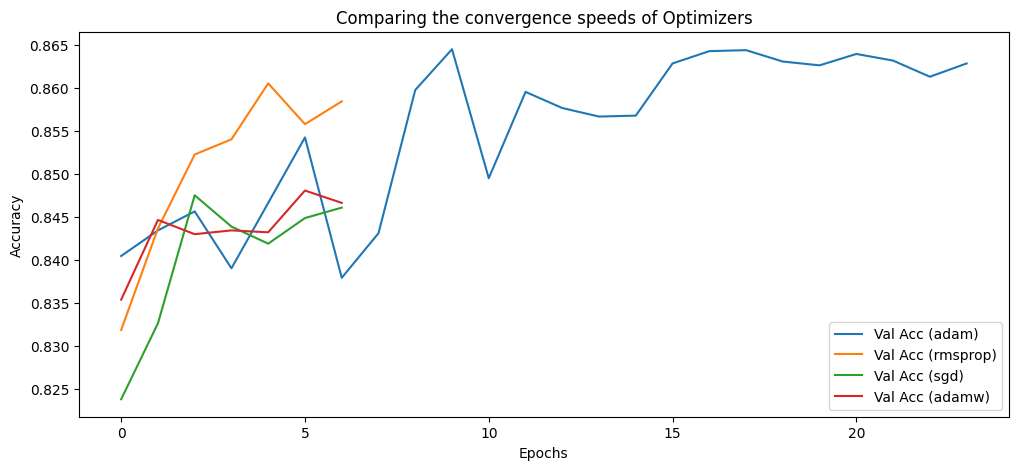

In [ ]:
plt.figure(figsize=(12, 5))
for opt, hist in history_dict.items():
    plt.plot(hist.history['val_accuracy'], label=f'Val Acc ({opt})')

plt.title('Comparing the convergence speeds of Optimizers')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**Model Tabnet**

In [ ]:
# Config of tabnet
tabnet_config = {
    "n_d": 32,               # Width of prediction layer (Chiều rộng của prediction layer)
    "n_a": 32,               # Width of attention layer (Chiều rộng của attention layer)
    "n_steps": 4,            # Number of processing steps (Số bước xử lý)
    "gamma": 1.3,            # Sparsity adjustment factor (Hệ số điều chỉnh sparsity)
    "lambda_sparse": 1e-4,   # Attention density constraint parameter (Tham số ràng buộc độ thưa của attention)
    "max_epochs": 100,
    "batch_size": 1024,      # TabNet prefers large batch sizes=
    "patience": 20,            # Stop early if no improvement after n epochs
    "n_independent": 2,
    "n_shared": 2
}

In [ ]:
from pytorch_tabnet.tab_model import TabNetClassifier
from pytorch_tabnet.pretraining import TabNetPretrainer
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import time

# ==========================================
# Verson 1: Standard Tabnet (No Pretrain)
# ==========================================
def train_and_eval_tabnet_base():
    print(f"\n" + "="*50)
    print(f"🚀 Starting: Standard TABNET (No Pretrain)")
    print("="*50)

    X_tr = X_train
    X_va = X_val
    X_te = X_test
    y_tr = y_train
    y_va = y_val
    y_te = y_test

    tabnet_model = TabNetClassifier(
        n_d=tabnet_config["n_d"],
        n_a=tabnet_config["n_a"],
        n_steps=tabnet_config["n_steps"],
        n_independent=tabnet_config["n_independent"],
        n_shared=tabnet_config["n_shared"],
        gamma=tabnet_config["gamma"],
        lambda_sparse=tabnet_config["lambda_sparse"],
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=1e-2, weight_decay=1e-4),
        scheduler_params={"step_size": 10, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        mask_type='entmax', device_name='auto'
    )

    start_time = time.time()
    tabnet_model.fit(
        X_train=X_tr,
        y_train=y_tr,
        eval_set=[(X_tr, y_tr), (X_va, y_va)],
        eval_name=['train', 'valid'],
        eval_metric=['auc', 'accuracy'],
        max_epochs=tabnet_config["max_epochs"],
        patience=tabnet_config["patience"],
        batch_size=tabnet_config["batch_size"],
        virtual_batch_size=256, num_workers=0, drop_last=False, weights=1
    )
    train_time = time.time() - start_time

    y_va_probs = tabnet_model.predict_proba(X_va)[:, 1]
    best_threshold, best_f1 = 0.5, 0
    for thresh in np.arange(0.3, 0.9, 0.001):
        val_pred = (y_va_probs > thresh).astype("int32")
        current_f1 = f1_score(y_va, val_pred, zero_division=0)
        if precision_score(y_va, val_pred, zero_division=0) >= 0.85 and current_f1 > best_f1:
            best_f1, best_threshold = current_f1, thresh

    y_pred = (tabnet_model.predict_proba(X_te)[:, 1] > best_threshold).astype("int32")
    metrics = {
        "Model": "TabNet (Standard)", "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_pred, zero_division=0),
        "Train Time (s)": round(train_time, 2), "Threshold": round(best_threshold, 3)
    }

    all_model_results.append({
        "Source": "Task 4 (Modern Tabular)",
        "Model Name": metrics["Model"],
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1-Score": metrics["F1-Score"]
    })
    return metrics


# ==========================================
# Version 2: Tabnet Having Pretrainning
# ==========================================
def train_and_eval_tabnet_pretrained():
    print(f"\n" + "="*50)
    print(f"🚀Starting: TABNET Having Pretrainning")
    print("="*50)

    X_tr = X_train
    X_va = X_val
    X_te = X_test
    y_tr = y_train
    y_va = y_val
    y_te = y_test

    start_time = time.time()

    # Step 1: Pretrain
    print("\n--- Step 1: Initialize Pretrainer---")
    unsupervised_model = TabNetPretrainer(
        n_d=tabnet_config["n_d"],
        n_a=tabnet_config["n_a"],
        n_steps=tabnet_config["n_steps"],
        n_independent=tabnet_config["n_independent"],
        n_shared=tabnet_config["n_shared"],
        gamma=tabnet_config["gamma"],
        lambda_sparse=tabnet_config["lambda_sparse"],
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type='entmax',
        device_name='auto'
    )
    unsupervised_model.fit(
        X_train=X_tr, eval_set=[X_va],
        max_epochs=100, patience=10,
        batch_size=tabnet_config["batch_size"],
        virtual_batch_size=256,
        num_workers=0,
        drop_last=False,
        pretraining_ratio=0.5
    )

    # Step 2: Classifier
    print("\n--- Step 2: Fine-Tunning Classifier ---")
    tabnet_model = TabNetClassifier(
        n_d=tabnet_config["n_d"],
        n_a=tabnet_config["n_a"],
        n_steps=tabnet_config["n_steps"],
        n_independent=tabnet_config["n_independent"],
        n_shared=tabnet_config["n_shared"],
        gamma=tabnet_config["gamma"],
        lambda_sparse=tabnet_config["lambda_sparse"],
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=1e-2, weight_decay=1e-4),
        scheduler_params={"step_size": 10, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        mask_type='entmax',
        device_name='auto'
    )

    tabnet_model.fit(
        X_train=X_tr, y_train=y_tr,
        eval_set=[(X_tr, y_tr), (X_va, y_va)],
        eval_name=['train', 'valid'],
        eval_metric=['auc', 'accuracy'],
        max_epochs=tabnet_config["max_epochs"],
        patience=tabnet_config["patience"],
        batch_size=tabnet_config["batch_size"],
        virtual_batch_size=256,
        num_workers=0,
        drop_last=False,
        weights=1,
        from_unsupervised=unsupervised_model
    )
    train_time = time.time() - start_time

    # Step 3: Find Thresold
    y_va_probs = tabnet_model.predict_proba(X_va)[:, 1]
    best_threshold, best_f1 = 0.5, 0
    for thresh in np.arange(0.4, 0.6, 0.001):
        val_pred = (y_va_probs > thresh).astype("int32")
        current_f1 = f1_score(y_va, val_pred, zero_division=0)
        if precision_score(y_va, val_pred, zero_division=0) >= 0.85 and current_f1 > best_f1:
            best_f1, best_threshold = current_f1, thresh

    # Step 4: Evaluate test
    y_pred = (tabnet_model.predict_proba(X_te)[:, 1] > best_threshold).astype("int32")
    metrics = {
        "Model": "TabNet (Pretrained)", "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_pred, zero_division=0),
        "Train Time (s)": round(train_time, 2), "Threshold": round(best_threshold, 3)
    }

    all_model_results.append({
        "Source": "Task 4 (Modern Tabular)",
        "Model Name": metrics["Model"],
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1-Score": metrics["F1-Score"]
    })
    return metrics

metrics_base = train_and_eval_tabnet_base()
metrics_pretrained = train_and_eval_tabnet_pretrained()

print("\n" + "="*150)
print(" Summmaring Table of TABNET")
print("\n" + "="*150)
df_tabnet_report = pd.DataFrame([metrics_base, metrics_pretrained])
print(df_tabnet_report.to_string(index=False))



🚀 Starting: Standard TABNET (No Pretrain)


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.6385  | train_auc: 0.87233 | train_accuracy: 0.76    | valid_auc: 0.87402 | valid_accuracy: 0.76271 |  0:00:06s
epoch 1  | loss: 0.39572 | train_auc: 0.89638 | train_accuracy: 0.75054 | valid_auc: 0.89656 | valid_accuracy: 0.75422 |  0:00:11s
epoch 2  | loss: 0.36981 | train_auc: 0.91036 | train_accuracy: 0.8169  | valid_auc: 0.9093  | valid_accuracy: 0.8163  |  0:00:16s
epoch 3  | loss: 0.3587  | train_auc: 0.91728 | train_accuracy: 0.82597 | valid_auc: 0.91716 | valid_accuracy: 0.82567 |  0:00:21s
epoch 4  | loss: 0.3503  | train_auc: 0.92357 | train_accuracy: 0.83556 | valid_auc: 0.92294 | valid_accuracy: 0.83184 |  0:00:27s
epoch 5  | loss: 0.33946 | train_auc: 0.92568 | train_accuracy: 0.82573 | valid_auc: 0.9246  | valid_accuracy: 0.82203 |  0:00:32s
epoch 6  | loss: 0.33566 | train_auc: 0.93078 | train_accuracy: 0.85326 | valid_auc: 0.92803 | valid_accuracy: 0.85147 |  0:00:37s
epoch 7  | loss: 0.32867 | train_auc: 0.93425 | train_accuracy: 0.84692 | valid_auc

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



🚀Starting: TABNET Having Pretrainning

--- Step 1: Initialize Pretrainer---


...

epoch 0  | loss: 102.29786| val_0_unsup_loss_numpy: 3.8803200721740723|  0:00:04s
epoch 1  | loss: 0.52295 | val_0_unsup_loss_numpy: 1.6715999841690063|  0:00:08s
epoch 2  | loss: 0.47298 | val_0_unsup_loss_numpy: 1.7129100561141968|  0:00:12s
epoch 3  | loss: 0.46492 | val_0_unsup_loss_numpy: 1.1325199604034424|  0:00:17s
epoch 4  | loss: 0.45247 | val_0_unsup_loss_numpy: 1.322540044784546|  0:00:21s
epoch 5  | loss: 0.43583 | val_0_unsup_loss_numpy: 1.057379961013794|  0:00:25s
epoch 6  | loss: 0.43245 | val_0_unsup_loss_numpy: 1.172160029411316|  0:00:29s
epoch 7  | loss: 0.42733 | val_0_unsup_loss_numpy: 0.8640999794006348|  0:00:33s
epoch 8  | loss: 0.42484 | val_0_unsup_loss_numpy: 0.9127900004386902|  0:00:38s
epoch 9  | loss: 0.41657 | val_0_unsup_loss_numpy: 0.9124600291252136|  0:00:42s
epoch 10 | loss: 0.41175 | val_0_unsup_loss_numpy: 0.9699000120162964|  0:00:46s
epoch 11 | loss: 0.41307 | val_0_unsup_loss_numpy: 0.914929986000061|  0:00:51s
epoch 12 | loss: 0.40553 | val_

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")
/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/abstract_model.py:248: UserWarning: Loading weights from unsupervised pretraining
  warnings.warn("Loading weights from unsupervised pretraining")


epoch 0  | loss: 0.52212 | train_auc: 0.89968 | train_accuracy: 0.80408 | valid_auc: 0.89719 | valid_accuracy: 0.80174 |  0:00:06s
epoch 1  | loss: 0.37273 | train_auc: 0.91958 | train_accuracy: 0.81383 | valid_auc: 0.91678 | valid_accuracy: 0.81475 |  0:00:12s
epoch 2  | loss: 0.35206 | train_auc: 0.92311 | train_accuracy: 0.83747 | valid_auc: 0.91969 | valid_accuracy: 0.8335  |  0:00:18s
epoch 3  | loss: 0.35041 | train_auc: 0.92058 | train_accuracy: 0.82812 | valid_auc: 0.91879 | valid_accuracy: 0.82688 |  0:00:23s
epoch 4  | loss: 0.33886 | train_auc: 0.92892 | train_accuracy: 0.83903 | valid_auc: 0.92595 | valid_accuracy: 0.83603 |  0:00:28s
epoch 5  | loss: 0.33078 | train_auc: 0.9334  | train_accuracy: 0.84378 | valid_auc: 0.92914 | valid_accuracy: 0.84067 |  0:00:33s
epoch 6  | loss: 0.32902 | train_auc: 0.93366 | train_accuracy: 0.85424 | valid_auc: 0.93067 | valid_accuracy: 0.85147 |  0:00:38s
epoch 7  | loss: 0.32329 | train_auc: 0.93523 | train_accuracy: 0.84904 | valid_auc

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



 Summmaring Table of TABNET

              Model  Accuracy  Precision   Recall  F1-Score  Train Time (s)  Threshold
  TabNet (Standard)  0.858598   0.842970 0.765895  0.802586          346.67      0.631
TabNet (Pretrained)  0.851145   0.796283 0.810789  0.803471          384.81      0.500


**Model NODE**

In [ ]:
# Config NODE
config_node = {
    "num_layers": 3,
    "num_trees": 512,
    "tree_depth": 6,
    "learning_rate": 0.001,
    "max_epochs": 50,
    "batch_size": 1024,
    "patience": 7
}

In [ ]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from pytorch_tabular import TabularModel
from pytorch_tabular.models import NodeConfig as TabularNodeConfig
from pytorch_tabular.config import DataConfig, OptimizerConfig, TrainerConfig

def train_and_eval_node():
    print(f"\n🌲 Training with NODE model (Optimized - No Redundant Tensors)")

    # 1. Load Data
    X_tr = X_train
    X_va = X_val
    X_te = X_test
    y_tr = y_train
    y_va = y_val
    y_te = y_test

    # 2. Clean Memory
    if os.path.exists('./saved_models'): shutil.rmtree('./saved_models')
    gc.collect()
    torch.cuda.empty_cache()

    # 3. Config Data
    feature_names = [f"feature_{i}" for i in range(X_tr.shape[1])]

    train_df = pd.DataFrame(X_tr, columns=feature_names)
    train_df['is_canceled'] = y_tr
    val_df = pd.DataFrame(X_va, columns=feature_names)
    val_df['is_canceled'] = y_va
    test_df = pd.DataFrame(X_te, columns=feature_names)

    data_config = DataConfig(target=['is_canceled'], continuous_cols=feature_names, categorical_cols=[])
    trainer_config = TrainerConfig(
        accelerator="gpu",
        devices=1,
        max_epochs=config_node["max_epochs"],
        batch_size=config_node["batch_size"],
        early_stopping_patience=config_node["patience"]
    )
    model_config = TabularNodeConfig(
        task="classification",
        num_layers=config_node["num_layers"],
        num_trees=config_node["num_trees"],
        depth=config_node["tree_depth"]
    )

    # 4. Init và Fit
    tabular_model = TabularModel(
        data_config=data_config,
        model_config=model_config,
        optimizer_config=OptimizerConfig(),
        trainer_config=trainer_config
    )

    tabular_model.fit(train=train_df, validation=val_df)

    # 5. Evaluated
    predictions = tabular_model.predict(test_df)
    prediction_col = [col for col in predictions.columns if 'prediction' in col.lower()][0]
    y_pred = predictions[prediction_col].values

    metrics = {
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_pred, zero_division=0)
    }

    all_model_results.append({
        "Source": "Task 4 (Modern NODE)",
        "Model Name": "NODE (Optimized)",
        **metrics
    })

    print(f"- NODE Optimized F1: {metrics['F1-Score']:.4f}")
    return tabular_model

node_model = train_and_eval_node()


🌲 Training with NODE model (Optimized - No Redundant Tensors)


2026-03-23 02:31:31,127 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off
INFO:lightning_fabric.utilities.seed:Seed set to 42
2026-03-23 02:31:31,160 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders
2026-03-23 02:31:31,330 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for classification task
2026-03-23 02:31:31,901 - {pytorch_tabular.tabular_model:598} - INFO - Preparing the Model: NODEModel
/usr/local/lib/python3.12/dist-packages/pytorch_tabular/models/node/node_model.py:111: UserWarning: Ignoring head config because NODE has a specific head which subsets the tree outputs
  warnings.warn("Ignoring head config because NODE has a specific head which subsets the tree outputs")
2026-03-23 02:31:32,177 - {pytorch_tabular.models.node.node_model:74} - INFO - Data Aware Initialization of NODE using a forward pass with 2000 batch size....
2026-03-23 02:31:57,943 - {pytorch_tabular.tabular_model:341} - INFO -

┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ NODEBackbone     │ 26.8 M │ train │     0 │
│ 1 │ _embedding_layer │ Embedding1dLayer │    592 │ train │     0 │
│ 2 │ _head            │ Lambda           │      0 │ train │     0 │
│ 3 │ loss             │ CrossEntropyLoss │      0 │ train │     0 │
└───┴──────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 26.8 M                                                                                           
Non-trainable params: 2.3 K                                                                                        
Total params: 26.8 M                                                                                               
Total estimated model params size (MB): 107                                                                        
Modules in train mode: 11                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=50` reached.


2026-03-23 03:07:42,859 - {pytorch_tabular.tabular_model:690} - INFO - Training the model completed
2026-03-23 03:07:42,861 - {pytorch_tabular.tabular_model:1531} - INFO - Loading the best model


- NODE Optimized F1: 0.8145


###**Task 5: Summarizing and Comparision (Tổng hợp và so sánh)**

In [ ]:
def finalize_comparison(results_list):
    # Generating DataFrame
    df_final = pd.DataFrame(results_list)

    # Sort by F1-Score
    df_final = df_final.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

    print("\n" + "="*150)
    print("- COMPARISION TABLE FOR TRADITIONAL AND MODERN MODEL")
    print("="*150)
    print(df_final.to_string(index=True))

    # Find best model
    best_model = df_final.iloc[0]
    print(f"\n- BEST MODEL: {best_model['Model Name']} from {best_model['Source']}")
    print(f"- Highest F1-Score: {best_model['F1-Score']:.4f}")
    return df_final

df_comparison = finalize_comparison(all_model_results)


- COMPARISION TABLE FOR TRADITIONAL AND MODERN MODEL
                     Source           Model Name  Accuracy  Precision    Recall  F1-Score
0      Task 4 (Modern NODE)     NODE (Optimized)  0.863229   0.829595  0.799859  0.814456
1                    Task 4           MLP (ADAM)  0.864111   0.845293  0.780820  0.811778
2   Task 4 (Modern Tabular)  TabNet (Pretrained)  0.851145   0.796283  0.810789  0.803471
3   Task 4 (Modern Tabular)    TabNet (Standard)  0.858598   0.842970  0.765895  0.802586
4             Task 3 (TC 4)                  SVM  0.838839   0.770293  0.813022  0.791081
5             Task 3 (TC 2)        Random Forest  0.855423   0.895270  0.696204  0.783287
6             Task 3 (TC 4)        Random Forest  0.854011   0.893804  0.693383  0.780940
7             Task 3 (TC 2)                  SVM  0.848145   0.852982  0.719356  0.780491
8                    Task 4        MLP (RMSPROP)  0.838971   0.845323  0.698790  0.765103
9                    Task 4          MLP (ADAM